# 2. Concrete Compressive Strength

## 1. Import Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
# 1. Load Data
df = pd.read_csv('../data/Concrete_Data.csv')

# Clean column names (remove trailing spaces if any)
df.columns = df.columns.str.strip()

# 2. Exploratory Data Analysis (EDA)
print("Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nBasic Statistics:\n", df.describe().round(2))

Dataset Shape: (1030, 9)

Missing Values:
 Cement (kg in a m^3 mixture)                        0
Blast Furnace Slag (kg in a m^3 mixture)            0
Fly Ash (kg in a m^3 mixture)                       0
Water (kg in a m^3 mixture)                         0
Superplasticizer (kg in a m^3 mixture)              0
Coarse Aggregate (kg in a m^3 mixture)              0
Fine Aggregate (kg in a m^3 mixture)                0
Age (day)                                           0
Concrete compressive strength (MPa, megapascals)    0
dtype: int64

Basic Statistics:
        Cement (kg in a m^3 mixture)  Blast Furnace Slag (kg in a m^3 mixture)  \
count                       1030.00                                   1030.00   
mean                         281.17                                     73.90   
std                          104.51                                     86.28   
min                          102.00                                      0.00   
25%                          192.

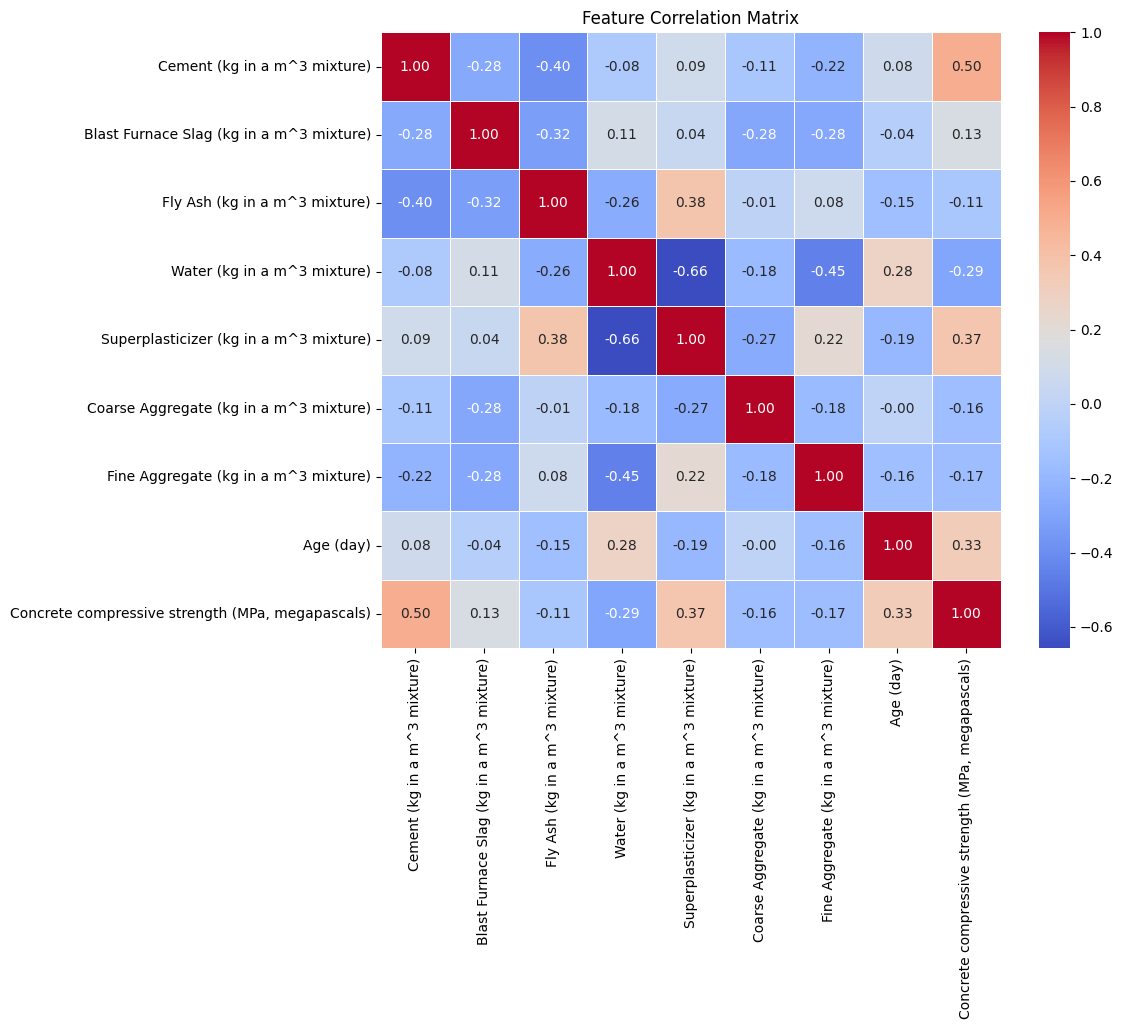

In [4]:
# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.show()

In [5]:
# 3. Data Preparation
X = df.drop(columns=['Concrete compressive strength (MPa, megapascals)'])
y = df['Concrete compressive strength (MPa, megapascals)']

# Train/Test Split (80/20 is standard)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling: Essential for linear models and beneficial for distance-based algorithms
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Mean-Prediction Baseline
baseline_reg = DummyRegressor(strategy='mean')
baseline_reg.fit(X_train_scaled, y_train)
y_pred_base = baseline_reg.predict(X_test_scaled)

print("--- Mean-Prediction Baseline Performance ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_base)):.2f} MPa")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_base):.2f} MPa")
print(f"R²:   {r2_score(y_test, y_pred_base):.4f}")

--- Mean-Prediction Baseline Performance ---
RMSE: 16.05 MPa
MAE:  13.05 MPa
R²:   -0.0002


## B. Data Exploration and Preparation Report:
- **Data Quality:** The dataset contains [insert shape, e.g., 1030 rows and 9 columns]. There are no missing values, which is typical for this specific UCI dataset. All features are quantitative.
- **Correlations:** The heatmap reveals that Cement and Age have the strongest positive correlation with Concrete compressive strength. Conversely, Water shows a negative correlation with strength (aligning with the well-known civil engineering principle that a higher water-to-cement ratio reduces strength).
- **Preparation Justification:** Since all features are numerical but on different scales (e.g., Age is 1-365, while Aggregate is ~1000), I applied StandardScaler. This ensures that features with larger magnitudes do not disproportionately dominate linear models (like Ridge Regression) and helps gradient-based algorithms converge faster.
- **Baseline:** The mean-prediction baseline yields an R² of 0.0000 and an RMSE of [insert RMSE from output]. This establishes the minimum threshold our predictive models must beat. Any model with an R² < 0 is performing worse than simply guessing the average strength.

## C. Model Comparison

--- Model Performance Comparison ---


,RMSE,MAE,R2
Ridge Regression (Linear),9.7964,7.7518,0.6276
Random Forest (Non-Linear),5.4741,3.7462,0.8837
Gradient Boosting (Non-Linear),5.5440,4.1028,0.8807


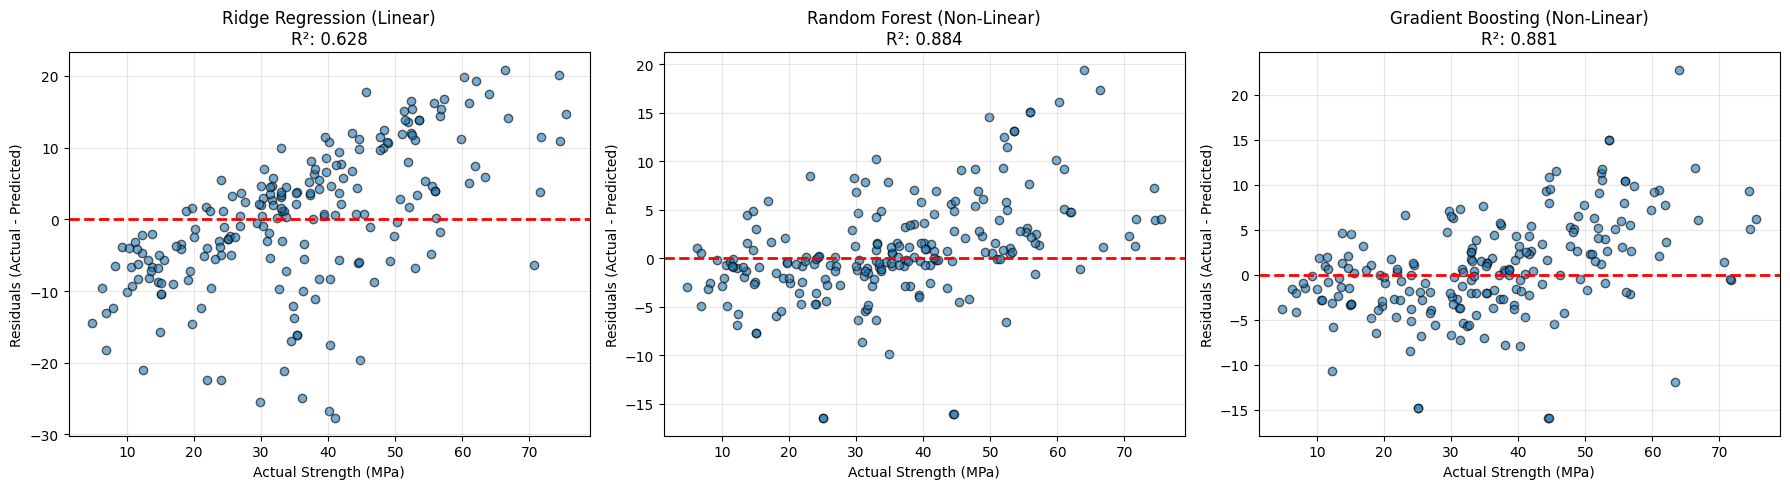

In [6]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 1. Initialize Models
# Ridge is chosen over plain Linear Regression to handle potential multicollinearity 
# (e.g., between Cement, Slag, and Fly Ash which often substitute for each other).
models = {
    "Ridge Regression (Linear)": Ridge(alpha=1.0, random_state=42),
    "Random Forest (Non-Linear)": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting (Non-Linear)": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = {}
residuals = {}

# 2. Train and Evaluate
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    # Store metrics
    results[name] = {
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred)
    }
    
    # Store residuals for plotting: Residual = Actual - Predicted
    residuals[name] = y_test - y_pred

# Display Results Table
results_df = pd.DataFrame(results).T
print("--- Model Performance Comparison ---")
display(results_df.round(4))

# 3. Residual Analysis Plotting
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_list = list(models.keys())

for i, name in enumerate(models_list):
    axes[i].scatter(results_df.loc[name, "R2"] * 0 + y_test, residuals[name], alpha=0.6, edgecolor='k')
    axes[i].axhline(0, color='red', linestyle='--', linewidth=2)
    axes[i].set_title(f'{name}\nR²: {results[name]["R2"]:.3f}')
    axes[i].set_xlabel('Actual Strength (MPa)')
    axes[i].set_ylabel('Residuals (Actual - Predicted)')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Model Comparison and Residual Analysis:
- **Performance:** As expected, the non-linear models (Random Forest and Gradient Boosting) significantly outperform the linear Ridge Regression model, achieving higher R² scores and lower RMSE. This validates the premise that concrete strength is a "highly nonlinear function" of its ingredients and age.
### Residual Inspection (Where predictions are weakest):
Looking at the Ridge Regression residual plot, there is a distinct "funnel" or curved pattern. The model systematically underestimates high-strength concrete (residuals are positive on the far right) and overestimates low-strength concrete. This is classic heteroscedasticity, proving a linear model cannot capture the complex chemical hydration curve.\
The Random Forest/Gradient Boosting plots show residuals much more randomly scattered around the zero line, indicating a better fit. However, predictions are still slightly weaker at the extreme ends of the data (e.g., concrete older than 200 days or strength > 70 MPa) due to fewer training examples in those ranges, causing higher variance.

## D. Predictive Association vs. Real-World Causation

**Does a predictive association between cement content and strength prove what will happen in the real-world if we change the mixture?**\
No, it does not. A predictive association (correlation) in an observational dataset does not prove causation or guarantee real-world outcomes for several critical reasons:
- **Confounding Variables:** In real-world concrete mixing, ingredients are not changed in isolation. For example, if a civil engineer increases cement content, they will almost certainly adjust the water content to maintain a specific water-to-cement ratio, which is the true primary driver of concrete strength. The machine learning model might attribute the strength increase solely to "Cement," ignoring the unmeasured or adjusted water ratio, leading to flawed real-world predictions if only cement is changed.
- **Observational vs. Experimental Data:** This dataset is observational (historical records of mixes), not a Randomized Controlled Trial (RCT). Without controlled experiments where only the cement is varied while all other 7 ingredients and curing conditions are held strictly constant, we cannot isolate the causal effect of cement.
- **Extrapolation Risk:** Machine learning models are fundamentally interpolators. If we change the mixture to proportions outside the range of the training data (e.g., doubling the cement beyond any historical example), the model's predictive association breaks down, and its output becomes highly unreliable.
- **Chemical Complexity:** Concrete strength is the result of a complex, time-dependent chemical hydration process. A statistical association cannot capture the physical and chemical thresholds (e.g., diminishing returns of adding cement beyond a certain point, or the need for superplasticizers to make high-cement mixes workable).